# Introducción a los datos
## Curso de Invierno — Microbioma de la rizósfera
### Instructor: David Alberto García-Estrada

⏱ **Duración estimada: ~2 h** (incluye un descanso de 10 min)

**Cómo usar este notebook:** las celdas marcadas con un **⌨️** las escribimos juntos, en vivo, siguiendo al instructor. Las demás ya vienen escritas: solo ejecútalas.  
Si te atrasas, copia el código del Etherpad o ejecuta la celda **🛟 Ponerse al día** más cercana.

## Objetivos de aprendizaje
Al completar esta lección, serás capaz de:
1. Distinguir tipos de datos y variables, y calcular medidas de resumen básicas con `pandas`.
2. Explicar qué es una tabla de abundancia de metagenomas y el formato BIOM, y cargarlos en Python.
3. Explorar un conjunto real de microbiomas: dimensiones, profundidad de secuenciación, prevalencia de taxones, contenido de la tabla y diversidad α.
4. Reconocer problemas típicos de datos reales (contaminación del hospedero, heterogeneidad técnica) y la diferencia entre **efecto de la planta** y **efecto del estudio**.

---

## 🔧 Setup y carga de datos (~10 min)

In [41]:
# Detección de entorno (VSCode local vs Google Colab) y preparación de datos
import os, sys, zipfile, urllib.request
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
LESSON = 'intro_datos'   # nombre de la carpeta de resultados de este notebook

# Subconjunto del taller en el repositorio (rama main)
SUBSET_URL = ('https://github.com/MicroAgroBiome/Curso_Invierno_2026/raw/main/datos/subset.zip')

if IN_COLAB:
    !pip install -q "scikit-bio>=0.6.2" biom-format
    BASE = Path('/content')
else:
    # Local: sube hasta encontrar la carpeta datos/ (repo clonado); si no existe, usa la carpeta actual
    BASE = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'datos').is_dir()), Path.cwd())

DATA_PATH = BASE / 'datos'
SUBSET_PATH = DATA_PATH / 'subset'
RESULTS_PATH = BASE / 'resultados' / LESSON

# Si los datos no están descomprimidos: usa el zip local o lo descarga del repo
if not (SUBSET_PATH / 'taller_genus.biom').exists():
    zip_path = DATA_PATH / 'subset.zip'
    if not zip_path.exists():
        DATA_PATH.mkdir(parents=True, exist_ok=True)
        print("Descargando datos del taller...")
        urllib.request.urlretrieve(SUBSET_URL, zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(DATA_PATH)

# Rutas como texto terminadas en '/', igual que antes: el resto del notebook no cambia
DATA_PATH, SUBSET_PATH, RESULTS_PATH = (str(p) + '/' for p in (DATA_PATH, SUBSET_PATH, RESULTS_PATH))

print(f"Entorno: {'Google Colab' if IN_COLAB else 'Local (VSCode)'}")
print(f"SUBSET_PATH:  {os.path.relpath(SUBSET_PATH)}")
print(f"RESULTS_PATH: {os.path.relpath(RESULTS_PATH)}")

Entorno: Local (VSCode)
SUBSET_PATH:  ../datos/subset
RESULTS_PATH: ../resultados/intro_datos


In [42]:
%matplotlib inline

# Imports y versiones
import numpy as np
import pandas as pd
import biom
import skbio
import skbio.diversity as div
import scipy
from scipy import stats
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

for lib in (pd, np, biom, skbio, scipy, sklearn, matplotlib, sns):
    print(f"{lib.__name__}: {lib.__version__}")

pandas: 3.0.6
numpy: 2.5.4
biom: 2.1.18
skbio: 0.7.4
scipy: 1.18.1
sklearn: 1.9.1
matplotlib: 3.11.2
seaborn: 0.13.2


### Los datos

Trabajaremos con **75 metagenomas de la rizósfera** de cultivos (tomate, maíz, soya, cacahuate, sorgo…) provenientes de **19 estudios** publicados. Son un subconjunto de un BIOM más grande (596 muestras), construido con `scripts/02_make_subset.py` con semilla fija; la lista exacta de muestras está en `datos/subset/taller_samples.csv`.

- `taller_genus.biom`: conteos de lecturas por **género** y muestra.
- `taller_metadata.csv`: información de cada muestra (planta hospedera, estudio, país, tipo de secuenciación…).

In [43]:
#| label: l1-cargar-datos
#| code-fold: true
# ⌨️ Carga la tabla BIOM, conviértela en DataFrame (muestras en filas) y lee los metadatos
biom_table = biom.load_table(SUBSET_PATH + "taller_genus.biom")
abundance_table = biom_table.to_dataframe(dense=True).T.round().astype("int64")
abundance_table.index.name = "sample_id"
metadata_df = pd.read_csv(SUBSET_PATH + "taller_metadata.csv", index_col=0)
abundance_table.shape, metadata_df.shape

((75, 3330), (75, 21))

In [44]:
# Verificación: ambas tablas describen las mismas muestras, en el mismo orden
assert list(abundance_table.index) == list(metadata_df.index)
print("✅ Las dos tablas tienen las mismas 75 muestras, en el mismo orden")

✅ Las dos tablas tienen las mismas 75 muestras, en el mismo orden


In [45]:
# 🛟 Celda de rescate: se llena sola en el notebook del participante
# (scripts/generar_notebook_participante.py). Aquí queda vacía a propósito.

---

## 📖 Sección 1: Fundamentos del análisis de datos

Antes de hablar de microbiomas, unos conceptos generales que usaremos en todo el taller.

**Tipos de análisis:**
- **Descriptivo:** resumir lo que hay en los datos (medias, proporciones, gráficas).
- **Exploratorio:** buscar patrones, relaciones y anomalías sin una hipótesis fija de antemano.
- **Inferencial:** generalizar de una muestra a una población y probar hipótesis.

**Estructura de un dataset tabular:**
- Cada **fila** es una observación (una muestra).
- Cada **columna** es una variable (un género microbiano, o en `metadata_df`, una característica de la muestra).

Exploramos primero `abundance_table` como *cualquier* tabla, sin preocuparnos aún de qué representa biológicamente.

In [46]:
#| label: l1-shape
#| code-fold: true
# ⌨️ Dimensiones de la tabla de abundancia: (filas, columnas)
abundance_table.shape

(75, 3330)

In [47]:
#| label: l1-iloc
#| code-fold: true
# ⌨️ Primeras 5 muestras y 6 géneros (para que quepa en pantalla)
abundance_table.iloc[:5, :6]

,Lactiplantibacillus,Lactobacillus,Ligilactobacillus,Limosilactobacillus,Companilactobacillus,Leuconostoc
sample_id,,,,,,
SRR12192850,87,150,66,152,27,156
SRR13062011,58,120,45,134,27,37
SRR11128413,63,317,140,108,101,140
SRR12964294,64,215,85,190,39,46
SRR12192805,55,154,57,151,26,46


**Tipos de variable:**
- **Numérica:** toma valores medibles.
- **Categórica:** toma un número limitado de categorías.

`pandas` los distingue con `.dtypes`:

In [48]:
# Columnas del metadato que usaremos como ejemplo
cols = ["host_name_family", "host_name", "country", "year", "latitude", "doi"]

In [49]:
#| label: l1-dtypes
#| code-fold: true
# ⌨️ Tipo de dato de cada columna
metadata_df[cols].dtypes

host_name_family        str
host_name               str
country                 str
year                float64
latitude            float64
doi                     str
dtype: object

In [50]:
#| label: l1-head
#| code-fold: true
# ⌨️ Primeras filas de esas columnas
metadata_df[cols].head()

,host_name_family,host_name,country,year,latitude,doi
sample_id,,,,,,
SRR12192850,Poaceae,Maize,South Africa,2021.0,-26.110000,10.3390/microorganisms9071419
SRR13062011,Poaceae,Maize,South Africa,2021.0,-25.994667,10.1128/MRA.01309-20
SRR11128413,Poaceae,Maize,South Africa,2020.0,-25.789989,10.1186/s13213-020-01591-8
SRR12964294,Poaceae,Maize,South Africa,2021.0,-26.152000,10.1007/s00203-021-02354-y
SRR12192805,Poaceae,Maize,South Africa,2020.0,-25.590000,10.1128/MRA.00860-20


**Medidas de resumen** para variables numéricas:
- **Media:** promedio.
- **Mediana:** valor central (menos sensible a valores extremos).
- **Desviación estándar:** qué tan dispersos están los valores respecto a la media.

`pandas` las calcula con métodos directos, o todas juntas con `.describe()`:

In [51]:
#| label: l1-resumen-genero
#| code-fold: true
# ⌨️ Media, mediana y desviación estándar de un género
genus = "Streptomyces"
print(abundance_table[genus].mean())
print(abundance_table[genus].median())
print(abundance_table[genus].std())

708963.4266666666
434022.0
824188.1510320154


#### 🔮 Predice antes de ejecutar
En la gráfica siguiente marcamos la media y la mediana de *Streptomyces*. ¿Cuál quedará más a la **derecha**? ¿Por qué? Escribe tu respuesta en el Etherpad y luego ejecuta la celda.

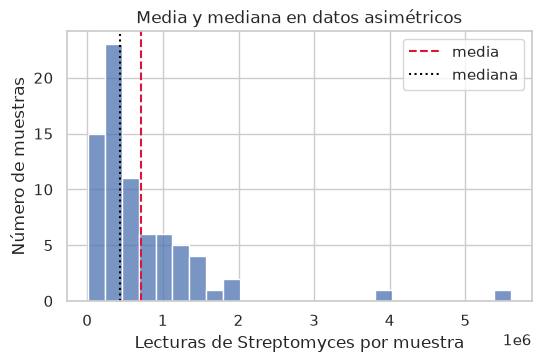

In [52]:
#| label: fig-l1-media-mediana
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Media y mediana de los conteos de *Streptomyces*: en datos asimétricos la media se aleja de la mediana."
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.histplot(abundance_table[genus], bins=25, ax=ax)
ax.axvline(abundance_table[genus].mean(), color="crimson", linestyle="--", label="media")
ax.axvline(abundance_table[genus].median(), color="black", linestyle=":", label="mediana")
ax.set_xlabel(f"Lecturas de {genus} por muestra")
ax.set_ylabel("Número de muestras")
ax.set_title("Media y mediana en datos asimétricos")
ax.legend()
plt.show()

In [53]:
#| label: l1-describe
#| code-fold: true
# ⌨️ Resumen de varias variables numéricas a la vez
metadata_df[["year", "latitude", "longitude", "fraction_resolved"]].describe().round(3)

,year,latitude,longitude,fraction_resolved
count,75.000,75.000,75.000,75.000
mean,2021.253,12.348,25.900,0.940
std,1.306,30.934,81.936,0.016
min,2016.000,-28.454,-121.700,0.899
25%,2021.000,-26.110,4.204,0.934
50%,2021.000,26.075,26.797,0.939
75%,2022.000,37.500,118.520,0.942
max,2023.000,56.000,127.970,0.993


---

## ✏️ Ejercicio 1: Media y desviación estándar de un género

**Instrucción:** calcula la media y la desviación estándar de los conteos del género `Pseudomonas` con `.mean()` y `.std()`. Reemplaza `TU_CODIGO_AQUI` por tu código. Tiempo estimado: 5 min.

In [54]:
genus_exercise = "Pseudomonas"

# ### TU CÓDIGO AQUÍ ###
genus_mean = TU_CODIGO_AQUI
genus_std = TU_CODIGO_AQUI

print(f"Media: {genus_mean:,.0f}")
print(f"Desviación estándar: {genus_std:,.0f}")

NameError: name 'TU_CODIGO_AQUI' is not defined

<details>
<summary>Ver solución</summary>

```python
genus_mean = abundance_table[genus_exercise].mean()
genus_std = abundance_table[genus_exercise].std()
```

Observa que la desviación estándar es **varias veces mayor** que la media: los conteos **crudos** varían muchísimo entre muestras. Parte de esa variación no es biológica, sino de cuánto se secuenció cada muestra. Lo veremos en la Sección 3.
</details>

---

## 📖 Sección 2: Introducción a datos biológicos (~20 min)

### ¿Qué es un microbioma?
Un **microbioma** es el conjunto de microorganismos (bacterias, arqueas, hongos, virus…) que habitan un ambiente. Aquí, la **rizósfera**: el suelo que rodea e influye las raíces de una planta. Estudiarlo permite entender cómo las plantas y su entorno moldean las comunidades microbianas.

### De las lecturas a una tabla de abundancia
Un **metagenoma** (secuenciación *shotgun*) secuencia fragmentos de ADN de *toda* la comunidad. Cada fragmento (**lectura**) se compara con una base de datos de referencia para asignarlo a un **taxón** (un grupo con nombre: un género, una especie…). Contar cuántas lecturas cayeron en cada taxón da la **tabla de abundancia**:

- **Filas:** muestras (en el BIOM original, al revés; aquí las transpusimos).
- **Columnas:** taxones. En este conjunto, **géneros**.
- **Valores:** número de lecturas asignadas a ese género en esa muestra.

> **Ojo:** en datos de amplicones (16S) se habla de **OTU/ASV**. Aquí no usamos OTU/ASV: las unidades son taxones asignados directamente por nombre.

### Rangos taxonómicos
Cada taxón se ubica en una jerarquía: **dominio → filo → clase → orden → familia → género → especie**. El BIOM original llegaba hasta especie; para este taller **colapsamos a género** (se suman las lecturas de todas las especies de cada género). Se descarta la pequeña fracción de lecturas que solo se pudo asignar a rangos más altos; la columna `fraction_resolved` del metadato dice qué fracción se conservó en cada muestra.

### El formato BIOM
Los datos se distribuyen en formato **BIOM** (*Biological Observation Matrix*): guarda los conteos de forma eficiente junto con **metadatos** de los taxones (su linaje) y de las muestras.

In [55]:
#| label: l1-biom-ids
#| code-fold: true
# ⌨️ Los primeros 5 géneros (en BIOM se llaman "observaciones")
biom_table.ids(axis="observation")[:5]

array(['Lactiplantibacillus', 'Lactobacillus', 'Ligilactobacillus',
       'Limosilactobacillus', 'Companilactobacillus'], dtype='<U41')

In [56]:
# El BIOM también guarda los nombres de las muestras y el linaje de cada género
print("Primeras muestras:", biom_table.ids(axis="sample")[:3].tolist())
print("Linaje de 'Rhizobium':", biom_table.metadata(id="Rhizobium", axis="observation")["taxonomy"])

Primeras muestras: ['SRR12192850', 'SRR13062011', 'SRR11128413']
Linaje de 'Rhizobium': ['k__Bacteria', 'p__Pseudomonadota', 'c__Alphaproteobacteria', 'o__Hyphomicrobiales', 'f__Rhizobiaceae', 'g__Rhizobium', 's__']


In [57]:
# Tabla de linajes: una fila por género, una columna por rango taxonómico
ranks = ["domain", "phylum", "class", "order", "family", "genus"]
taxonomy_df = pd.DataFrame(
    [[name.split("__", 1)[1] for name in meta["taxonomy"][:6]]
    for meta in biom_table.metadata(axis="observation")],
    index=biom_table.ids(axis="observation"), columns=ranks)

taxonomy_df.loc[["Streptomyces", "Rhizobium", "Pseudomonas"]]

,domain,phylum,class,order,family,genus
Streptomyces,Bacteria,Actinomycetota,Actinomycetes,Kitasatosporales,Streptomycetaceae,Streptomyces
Rhizobium,Bacteria,Pseudomonadota,Alphaproteobacteria,Hyphomicrobiales,Rhizobiaceae,Rhizobium
Pseudomonas,Bacteria,Pseudomonadota,Gammaproteobacteria,Pseudomonadales,Pseudomonadaceae,Pseudomonas


### Las muestras: qué sabemos de cada una
`metadata_df` describe cada muestra. Tres variables serán centrales: la **planta hospedera** (`host_name`, agrupada en `host_name_family`), el **estudio** de origen (`doi`) y el **país**.

In [58]:
#| label: tbl-l1-plantas
#| tbl-cap: "Plantas hospederas incluidas en cada familia."
#| code-fold: true
# ⌨️ ¿Qué plantas hay en cada familia? Tabla cruzada de dos columnas del metadato
pd.crosstab(metadata_df["host_name_family"], metadata_df["host_name"])

host_name,Common bean,Gramineae,Maize,Pea,Peanut,Purple bush-bean,Red pepper,Sorghum,Soya bean,Tomato,Wheat
host_name_family,,,,,,,,,,,
Fabaceae,2,0,0,3,8,1,0,0,11,0,0
Poaceae,0,2,17,0,0,0,0,4,0,0,2
Solanaceae,0,0,0,0,0,0,4,0,0,21,0


### Uniendo abundancia y metadatos
Para analizar por planta necesitamos combinar los conteos con el metadato. Ambas tablas comparten el índice `sample_id`, así que podemos usar `.join()`:

In [59]:
#| label: l1-join
#| code-fold: true
# ⌨️ Une conteos y metadatos por el índice común (sample_id)
merged_table = abundance_table.join(metadata_df)
merged_table[["Streptomyces", "Rhizobium", "host_name_family", "host_name"]].head()

,Streptomyces,Rhizobium,host_name_family,host_name
sample_id,,,,
SRR12192850,354268,22428,Poaceae,Maize
SRR13062011,230493,20032,Poaceae,Maize
SRR11128413,7900,1692,Poaceae,Maize
SRR12964294,434022,26746,Poaceae,Maize
SRR12192805,278332,16203,Poaceae,Maize


---

## ✏️ Ejercicio 2: Filtrar por familia de planta

**Instrucción:** a partir de `merged_table`, filtra solo las muestras de la familia `"Fabaceae"` (leguminosas) y cuenta cuántas hay. Tiempo estimado: 5 min.

In [60]:
# ### TU CÓDIGO AQUÍ ###
fabaceae_samples = merged_table[merged_table["host_name_family"] == TU_CODIGO_AQUI]

print(f"Muestras de Fabaceae: {fabaceae_samples.shape[0]}")
print(fabaceae_samples["host_name"].value_counts())

NameError: name 'TU_CODIGO_AQUI' is not defined

<details>
<summary>Ver solución</summary>

```python
fabaceae_samples = merged_table[merged_table["host_name_family"] == "Fabaceae"]
```

</details>

---

## 📖 Sección 3: Análisis exploratorio de datos

Ahora un primer recorrido exploratorio de datos reales: ¿qué contiene la tabla?, ¿qué tan profundamente se secuenció cada muestra?, ¿qué tan comunes son los géneros?, ¿cuánta diversidad hay?

### 3.1 Dimensiones y diseño del estudio

In [61]:
# 🛟 Celda de rescate: se llena sola en el notebook del participante
# (scripts/generar_notebook_participante.py). Aquí queda vacía a propósito.

In [62]:
# Identificador corto y ordenado para cada estudio: E01, E02, ...
studies = sorted(metadata_df["doi"].unique())
metadata_df["study_id"] = metadata_df["doi"].map({doi: f"E{i + 1:02d}" for i, doi in enumerate(studies)})

print(f"Muestras: {abundance_table.shape[0]} | géneros: {abundance_table.shape[1]} | estudios: {len(studies)}")
print()
print(pd.DataFrame({"muestras": metadata_df["host_name_family"].value_counts(),
                    "estudios": metadata_df.groupby("host_name_family")["study_id"].nunique()}))

Muestras: 75 | géneros: 3330 | estudios: 19

                  muestras  estudios
host_name_family                    
Fabaceae                25         4
Poaceae                 25        11
Solanaceae              25         6


Pregunta importante para todo lo que sigue: **¿cuántas familias de planta distintas aporta cada estudio?**

In [63]:
#| label: l1-study-family
#| code-fold: true
# ⌨️ Tabla cruzada: número de muestras por estudio y familia de planta
study_family = pd.crosstab(metadata_df["study_id"], metadata_df["host_name_family"])
study_family.head()

host_name_family,Fabaceae,Poaceae,Solanaceae
study_id,,,
E01,0,3,0
E02,0,0,1
E03,3,0,0
E04,0,2,0
E05,0,0,6


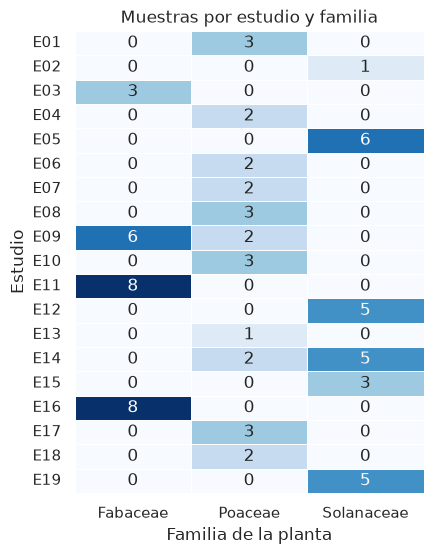

Estudios según el número de familias de planta que incluyen:
1    17
2     2
Name: count, dtype: int64


In [64]:
#| label: fig-l1-estudio-familia
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Número de muestras por estudio y familia de planta: casi cada estudio muestreó una sola familia."
fig, ax = plt.subplots(figsize=(4.5, 6))
sns.heatmap(study_family, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5, ax=ax)
ax.set_xlabel("Familia de la planta")
ax.set_ylabel("Estudio")
ax.set_title("Muestras por estudio y familia")
plt.show()

families_per_study = study_family.gt(0).sum(axis=1)
print("Estudios según el número de familias de planta que incluyen:")
print(families_per_study.value_counts().sort_index())

Casi cada estudio muestreó **una sola familia de planta**. Eso significa que *planta* y *estudio* (con su laboratorio, su suelo, su protocolo) están entrelazados: si dos familias se ven distintas, no sabremos si es por la planta o por el estudio. Volveremos a esto en el capítulo *Técnicas de clustering*.

### 3.2 ¿Qué contiene realmente la tabla?
Antes de analizar, revisemos de qué dominios de la vida son las lecturas:

#### 🔮 Predice antes de ejecutar
Vamos a dividir cada conteo entre el total de lecturas de su muestra (**abundancia relativa**). Después, ¿cuánto debería sumar cada fila?

In [65]:
#| label: l1-relativa
#| code-fold: true
# ⌨️ Abundancia relativa: cada conteo entre el total de lecturas de su muestra
relative_raw = abundance_table.div(abundance_table.sum(axis=1), axis=0)
relative_raw.sum(axis=1).head()

sample_id
SRR12192850    1.0
SRR13062011    1.0
SRR11128413    1.0
SRR12964294    1.0
SRR12192805    1.0
dtype: float64

In [66]:
# Suma por dominio en cada muestra, y promedio entre muestras (en %)
by_domain = relative_raw.T.groupby(taxonomy_df["domain"]).sum().T
(by_domain.mean() * 100).round(2).sort_values(ascending=False)

domain
Bacteria     96.60
Eukaryota     2.32
Archaea       0.87
Viruses       0.21
dtype: float64

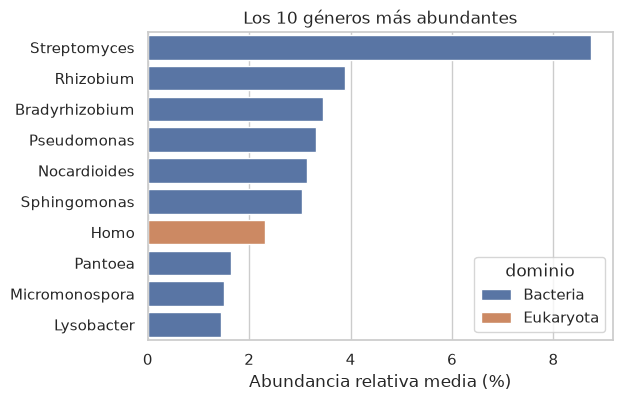

In [67]:
#| label: fig-l1-top-generos
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Los 10 géneros con mayor abundancia relativa media, coloreados por dominio."
# Los 10 géneros más abundantes (promedio entre muestras), coloreados por dominio
top_genera = (relative_raw.mean() * 100).sort_values(ascending=False).head(10)
top_df = pd.DataFrame({"genero": top_genera.index, "abundancia": top_genera.values,
                       "dominio": taxonomy_df.loc[top_genera.index, "domain"].to_numpy()})

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=top_df, y="genero", x="abundancia", hue="dominio", dodge=False, ax=ax)
ax.set_xlabel("Abundancia relativa media (%)")
ax.set_ylabel("")
ax.set_title("Los 10 géneros más abundantes")
plt.show()

Entre los géneros más abundantes aparece **`Homo`** — es ADN **humano**, no microbiano (contaminación durante el muestreo o la preparación, o lecturas del propio hospedero). ¿En cuántas muestras es importante?

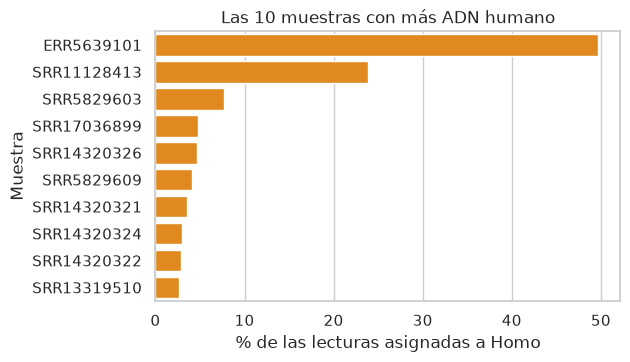

In [68]:
#| label: fig-l1-homo
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Porcentaje de lecturas asignadas a *Homo* en las 10 muestras más afectadas."
homo_pct = (relative_raw["Homo"] * 100).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(x=homo_pct.to_numpy(), y=homo_pct.index.to_numpy(), color="darkorange", ax=ax)
ax.set_xlabel("% de las lecturas asignadas a Homo")
ax.set_ylabel("Muestra")
ax.set_title("Las 10 muestras con más ADN humano")
plt.show()

Para estudiar la comunidad **procariota**, nos quedamos con **Bacteria y Archaea**; descartamos `Homo` y los virus (que aportan muy pocas lecturas). Es una **decisión de análisis**, no un estándar: otros estudios conservarían hongos o virus. Lo importante es dejarla explícita.

In [69]:
#| label: l1-procariotas
#| code-fold: true
# ⌨️ Conserva solo los géneros de Bacteria y Archaea
prokaryotes = taxonomy_df.index[taxonomy_df["domain"].isin(["Bacteria", "Archaea"])]
abundance_clean = abundance_table[prokaryotes]
abundance_clean.shape

(75, 2129)

### 3.3 ¿Quién vive ahí? Composición por filo  ⏭ *opcional*
Una vista clásica de un microbioma: **una barra por muestra**, dividida según la abundancia relativa de cada **filo**. Ordenamos las muestras por familia de planta y etiquetamos cada barra con su estudio:

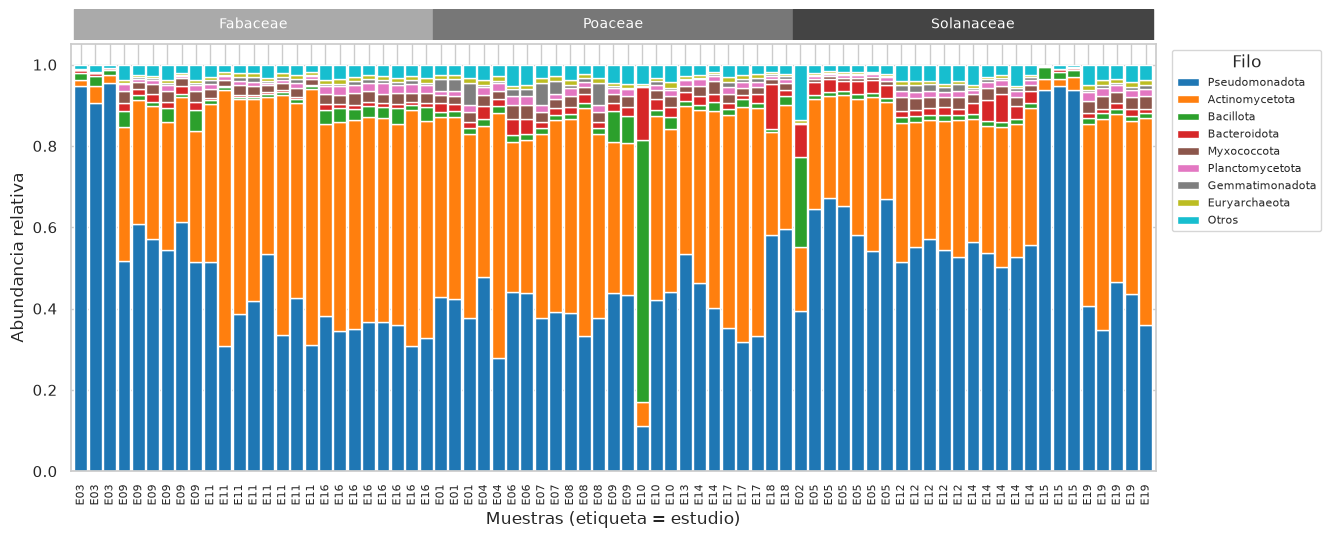

In [70]:
#| label: fig-l1-filos
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Composición por filo de cada muestra, ordenadas por familia de planta (etiqueta = estudio)."
phylum = taxonomy_df.loc[prokaryotes, "phylum"]
relative_clean = abundance_clean.div(abundance_clean.sum(axis=1), axis=0)
by_phylum = relative_clean.T.groupby(phylum).sum().T                 # muestras x filos

top_phyla = by_phylum.mean().sort_values(ascending=False).head(8).index
phylum_plot = by_phylum[top_phyla].assign(Otros=1 - by_phylum[top_phyla].sum(axis=1))

order = metadata_df.sort_values(["host_name_family", "study_id"]).index
families_sorted = metadata_df.loc[order, "host_name_family"].to_numpy()

fig, (strip, ax) = plt.subplots(2, 1, figsize=(14, 6), sharex=True,
                                gridspec_kw={"height_ratios": [1, 14], "hspace": 0.02})
# Franja superior: familia de la planta
for shade, fam in zip(["#aaaaaa", "#777777", "#444444"], sorted(metadata_df["host_name_family"].unique())):
    pos = np.where(families_sorted == fam)[0]
    strip.axvspan(pos.min() - 0.5, pos.max() + 0.5, color=shade)
    strip.text(pos.mean(), 0.5, fam, ha="center", va="center", color="white", fontsize=10)
strip.set_ylim(0, 1)
strip.axis("off")

phylum_plot.loc[order].reset_index(drop=True).plot(kind="bar", stacked=True, width=0.9, ax=ax, colormap="tab10", legend=False)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(metadata_df.loc[order, "study_id"], rotation=90, fontsize=8)
ax.set_xlabel("Muestras (etiqueta = estudio)")
ax.set_ylabel("Abundancia relativa")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", title="Filo", fontsize=8)
plt.show()

Dos filos dominan casi todas las muestras. Fíjate en lo que **se sale del patrón** (barras muy distintas de sus vecinas) y en qué estudios están.

### 3.4 Profundidad de secuenciación
La **profundidad** de una muestra es su total de lecturas (suma de todos los géneros). Varía entre muestras por razones técnicas, no solo biológicas.

In [71]:
# 🛟 Celda de rescate: se llena sola en el notebook del participante
# (scripts/generar_notebook_participante.py). Aquí queda vacía a propósito.

In [72]:
#| label: l1-profundidad
#| code-fold: true
# ⌨️ Profundidad: total de lecturas (de Bacteria + Archaea) de cada muestra
depth_clean = abundance_clean.sum(axis=1)
depth_clean.describe()

count    7.500000e+01
mean     1.018285e+07
std      1.731700e+07
min      7.508800e+05
25%      2.791851e+06
50%      4.794354e+06
75%      9.973098e+06
max      1.024900e+08
dtype: float64

In [73]:
print(f"La muestra más profunda tiene {depth_clean.max() / depth_clean.min():.0f} veces más lecturas que la menos profunda")

La muestra más profunda tiene 136 veces más lecturas que la menos profunda


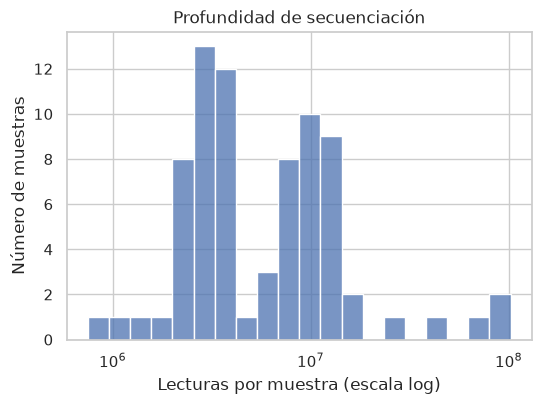

In [74]:
#| label: fig-l1-profundidad
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Distribución de la profundidad de secuenciación (lecturas de Bacteria + Archaea por muestra)."
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(depth_clean, bins=20, log_scale=True, ax=ax)   # escala logarítmica: el rango es enorme
ax.set_xlabel("Lecturas por muestra (escala log)")
ax.set_ylabel("Número de muestras")
ax.set_title("Profundidad de secuenciación")
plt.show()

### 3.5 Prevalencia de géneros
La **prevalencia** de un género es en cuántas muestras aparece (conteo > 0).

In [75]:
#| label: l1-prevalencia
#| code-fold: true
# ⌨️ Prevalencia: en cuántas muestras aparece cada género (conteo > 0)
prevalence = (abundance_clean > 0).sum(axis=0)
prevalence.describe()

count    2129.000000
mean       74.171442
std         4.655138
min         8.000000
25%        75.000000
50%        75.000000
75%        75.000000
max        75.000000
dtype: float64

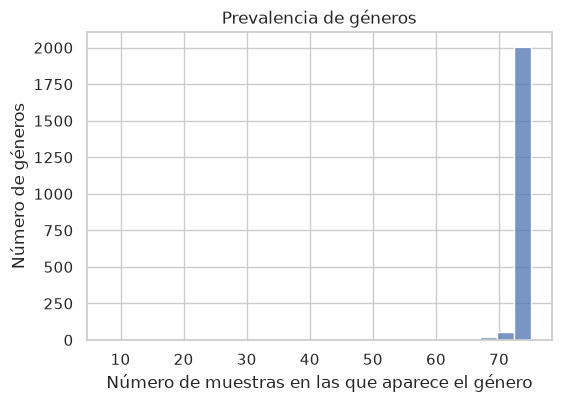

Géneros presentes en TODAS las muestras: 1774 de 2129
Géneros presentes en 10 muestras o menos: 3


In [76]:
#| label: fig-l1-prevalencia
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Prevalencia de géneros: en cuántas de las 75 muestras aparece cada uno."
n_samples = abundance_clean.shape[0]

fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(prevalence, bins=25, ax=ax)
ax.set_xlabel("Número de muestras en las que aparece el género")
ax.set_ylabel("Número de géneros")
ax.set_title("Prevalencia de géneros")
plt.show()

print(f"Géneros presentes en TODAS las muestras: {(prevalence == n_samples).sum()} de {len(prevalence)}")
print(f"Géneros presentes en 10 muestras o menos: {(prevalence <= 10).sum()}")

La tabla es **muy densa**: la mayoría de los géneros aparece en casi todas las muestras. Con secuenciación tan profunda, incluso géneros raros dejan algunas lecturas. Consecuencia práctica: contar *cuántos* géneros hay (riqueza) distingue poco entre muestras. Lo comprobamos a continuación.

### 3.6 Diversidad α
La **diversidad α** resume una muestra con un número. Tres métricas:
- **Riqueza:** cuántos géneros se detectan.
- **Shannon:** combina riqueza y equidad (qué tan parejas son las abundancias). Más alto = más diverso.
- **Simpson:** da más peso a los géneros dominantes.

In [77]:
# 🛟 Celda de rescate: se llena sola en el notebook del participante
# (scripts/generar_notebook_participante.py). Aquí queda vacía a propósito.

In [78]:
#| label: l1-alfa
#| code-fold: true
# ⌨️ Diversidad α de cada muestra: riqueza y Shannon
richness = (abundance_clean > 0).sum(axis=1)
shannon = div.alpha_diversity("shannon", abundance_clean.values, ids=abundance_clean.index)
metadata_df["shannon"] = shannon
metadata_df["shannon"].head()

sample_id
SRR12192850    5.272558
SRR13062011    5.395397
SRR11128413    3.147601
SRR12964294    5.175720
SRR12192805    5.300802
Name: shannon, dtype: float64

#### 🔮 Predice antes de ejecutar
¿Las muestras con **más lecturas** tendrán **más géneros detectados**, menos, o no habrá relación? Anótalo y después calcula la correlación de Spearman.

In [79]:
#| label: l1-spearman
#| code-fold: true
# ⌨️ Correlación de Spearman entre profundidad y riqueza
stats.spearmanr(depth_clean, richness)

SignificanceResult(statistic=np.float64(0.48199783609120694), pvalue=np.float64(1.1949888395618184e-05))

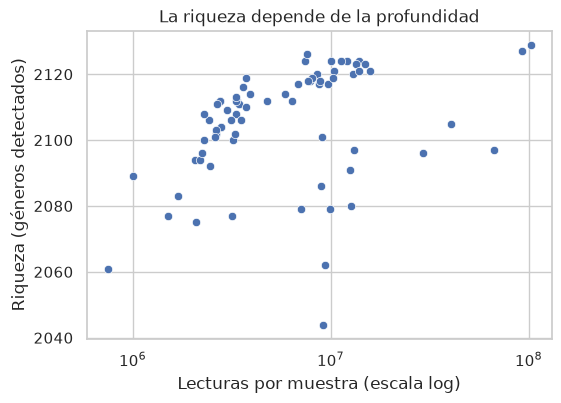

In [80]:
#| label: fig-l1-riqueza-profundidad
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Riqueza de géneros frente a la profundidad de secuenciación."
alpha_df = pd.DataFrame({"richness": richness, "shannon": shannon, "depth": depth_clean})

fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(data=alpha_df, x="depth", y="richness", ax=ax)
ax.set_xscale("log")
ax.set_xlabel("Lecturas por muestra (escala log)")
ax.set_ylabel("Riqueza (géneros detectados)")
ax.set_title("La riqueza depende de la profundidad")
plt.show()

Ahora comparemos la diversidad de Shannon entre familias de plantas, con una prueba de **Kruskal-Wallis** (compara grupos sin suponer distribución normal):

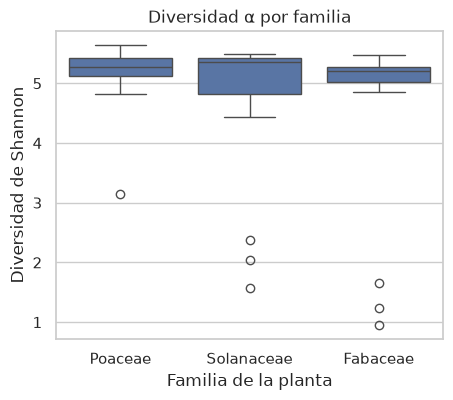

host_name_family
Fabaceae      5.20
Poaceae       5.27
Solanaceae    5.35
Name: shannon, dtype: float64


In [81]:
#| label: fig-l1-shannon-familia
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Diversidad de Shannon por familia de planta."
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=metadata_df, x="host_name_family", y="shannon", ax=ax)
ax.set_xlabel("Familia de la planta")
ax.set_ylabel("Diversidad de Shannon")
ax.set_title("Diversidad α por familia")
plt.show()

# Un arreglo de valores de Shannon por familia, y sus medianas
groups = [g["shannon"].values for _, g in metadata_df.groupby("host_name_family")]
print(metadata_df.groupby("host_name_family")["shannon"].median().round(2))

In [82]:
#| label: l1-kruskal
#| code-fold: true
# ⌨️ Prueba de Kruskal-Wallis: ¿difiere Shannon entre las tres familias?
stats.kruskal(*groups)

KruskalResult(statistic=np.float64(2.9420197738103866), pvalue=np.float64(0.2296934036578365))

**¿Y el estudio?** La misma diversidad, ahora por estudio y coloreada por familia:

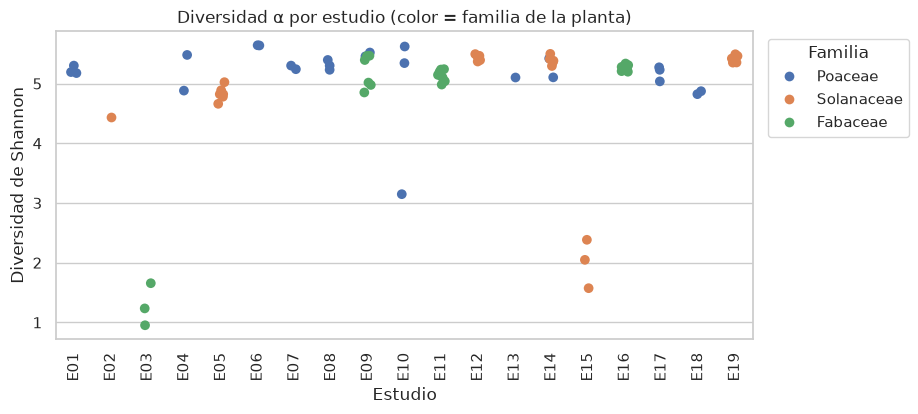

In [83]:
#| label: fig-l1-shannon-estudio
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Diversidad de Shannon por estudio, coloreada por familia de planta."
fig, ax = plt.subplots(figsize=(9, 4))
sns.stripplot(data=metadata_df, x="study_id", y="shannon", hue="host_name_family",
              order=sorted(metadata_df["study_id"].unique()), size=7, ax=ax)
ax.set_xlabel("Estudio")
ax.set_ylabel("Diversidad de Shannon")
ax.set_title("Diversidad α por estudio (color = familia de la planta)")
ax.legend(title="Familia", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=90)
plt.show()

---

## ✏️ Ejercicio 3: Interpretar las figuras de diversidad

**Instrucción:** con las dos figuras anteriores (Shannon por familia y por estudio) y el resultado de Kruskal-Wallis, responde en el Etherpad. No hace falta escribir código. Tiempo estimado: 5 min.

1. ¿Hay una diferencia significativa de Shannon entre familias de planta? ¿En qué te basas?
2. ¿Qué varía más: la diversidad entre **familias** o entre **estudios**?
3. ¿Qué implica tu respuesta anterior si quisieras concluir algo sobre el efecto de la planta?

<details>
<summary>Ver solución</summary>

1. No: las medianas de las tres familias son muy parecidas y Kruskal-Wallis da p > 0.05.
2. Entre **estudios**: algunos estudios tienen valores de Shannon muy por debajo del resto, mientras que las familias se traslapan casi por completo.
3. Como casi cada estudio muestreó una sola familia, una diferencia entre familias podría deberse al estudio (suelo, laboratorio, protocolo). Con este diseño no se pueden separar; lo retomamos en el capítulo *Técnicas de clustering*.
</details>

<details>
<summary>📝 Notas del instructor (cifras verificadas con el subconjunto)</summary>

- **Dominios** (abundancia relativa media): Bacteria 96.60 % · Eukaryota 2.32 % (casi todo `Homo`) · Archaea 0.87 % · Virus 0.21 %.
- **Homo**: ERR5639101 49.7 %, SRR11128413 23.9 %, SRR5829603 7.7 %; el resto de las muestras, mucho menos.
- **Profundidad** (solo Bacteria + Archaea): mínimo 750,880 · mediana 4,794,354 · máximo 102,490,010 lecturas (136 veces).
- **Prevalencia**: 1,774 de 2,129 géneros están en las 75 muestras; solo 3 aparecen en 10 muestras o menos.
- **Riqueza vs profundidad**: Spearman ρ = 0.48 (p = 1.2e-05).
- **Shannon por familia** (medianas): Fabaceae 5.20 · Poaceae 5.27 · Solanaceae 5.35; Kruskal-Wallis p = 0.230 (sin diferencia significativa).
- **Figura por estudio**: E03 (frijol, México) tiene Shannon 1.0–1.7 y E15 (pimiento, Corea) 1.6–2.4; el resto de las muestras va de 3.1 a 5.6. La variación **entre estudios** supera a la que hay entre familias.
</details>

---

## ✏️ Ejercicio 4: Cambiar de métrica y comparar

**Instrucción:** cambia la métrica de `"shannon"` a `"simpson"`, recalcula la mediana por familia y la prueba de Kruskal-Wallis, y compara: **¿cambia la conclusión sobre las familias?** Tiempo estimado: 10 min.

In [84]:
# ### TU CÓDIGO AQUÍ ### — cambia la métrica
metric = "TU_CODIGO_AQUI"   # usa "simpson" en vez de "shannon"

metadata_df[metric] = div.alpha_diversity(metric, abundance_clean.values, ids=abundance_clean.index)

groups = [g[metric].values for _, g in metadata_df.groupby("host_name_family")]
stat, p_value = stats.kruskal(*groups)
print(metadata_df.groupby("host_name_family")[metric].median().round(3))
print(f"\nKruskal-Wallis: estadístico = {stat:.2f}, p = {p_value:.3f}")

ValueError: "TU_CODIGO_AQUI" is not an available alpha diversity metric name. Refer to `get_alpha_diversity_metrics` for a list of available metrics.

<details>
<summary>Ver solución</summary>

```python
metric = "simpson"
```

Medianas de Simpson por familia: Fabaceae 0.977 · Poaceae 0.979 · Solanaceae 0.981; Kruskal-Wallis p = 0.115. Como con Shannon, **no hay diferencia significativa** entre familias (p > 0.05): la conclusión no cambia. Ojo: Simpson casi no varía porque con tantos géneros su valor se satura cerca de 1.
</details>

---

## 📊 Resumen de la lección

- Un dataset tabular tiene observaciones (filas) y variables (columnas), numéricas o categóricas; las resumimos con `pandas`.
- Una tabla de abundancia de metagenomas tiene muestras en las filas y taxones (aquí géneros) en las columnas; el formato BIOM guarda esto junto con los linajes y metadatos.
- Un EDA con datos reales **revela problemas**: ADN humano (`Homo`), profundidades muy desiguales, una tabla muy densa donde la riqueza discrimina poco, y metadatos con heterogeneidad técnica.
- Planta y estudio están **entrelazados**: casi todos los estudios muestrearon una sola familia de plantas.

**Conexión con el capítulo *Técnicas de clustering*:** calcularemos **distancias** entre muestras (Bray-Curtis), las visualizaremos (PCoA) y haremos **clustering** para preguntar: *¿los grupos que aparecen siguen a la planta o al estudio?*

---

## 💾 Exportar resultados para la siguiente lección

In [85]:
# 🛟 Celda de rescate: se llena sola en el notebook del participante
# (scripts/generar_notebook_participante.py). Aquí queda vacía a propósito.

In [86]:
import os
os.makedirs(RESULTS_PATH, exist_ok=True)

# Simpson siempre se exporta (no depende de si se hizo el Ejercicio 3)
metadata_df["simpson"] = div.alpha_diversity("simpson", abundance_clean.values, ids=abundance_clean.index)
metadata_df["richness"] = richness
metadata_df["depth_clean"] = depth_clean

abundance_clean.to_csv(RESULTS_PATH + "intro_datos_tabla_abundancia_limpia.csv")
metadata_df.to_csv(RESULTS_PATH + "intro_datos_metadata_diversidad.csv")
taxonomy_df.loc[prokaryotes].to_csv(RESULTS_PATH + "intro_datos_taxonomia.csv")

print(f"Exportado en: {os.path.relpath(RESULTS_PATH)}")
print("  - intro_datos_tabla_abundancia_limpia.csv  (conteos, Bacteria + Archaea)")
print("  - intro_datos_metadata_diversidad.csv      (metadato + study_id + diversidad α)")
print("  - intro_datos_taxonomia.csv                (linaje de cada género)")

Exportado en: ../resultados/intro_datos
  - intro_datos_tabla_abundancia_limpia.csv  (conteos, Bacteria + Archaea)
  - intro_datos_metadata_diversidad.csv      (metadato + study_id + diversidad α)
  - intro_datos_taxonomia.csv                (linaje de cada género)
